# Problem Set 4 - Learning

Submitted by: <b>Lanuzo, Jessica Mae T. | BSCS-2A </b>
***
Explore at least one (1) machine learning algorithm either in classification, regression or clustering task using a dataset from UCI Machine Learning Repository.

     The Algorithm: Logistic Regression
> Logistic regression estimates the probability of an event occurring, such as voted or didn’t vote, based on a given data set of independent variables. (© IBM)

> It is used to describe data and to explain the relationship between one dependent binary variable and one or more nominal, ordinal, interval or ratio-level independent variables. (© Statistics Solutions 2024)

> https://scikit-learn.org/1.5/modules/generated/sklearn.linear_model.LogisticRegression.html

     The Dataset: Tic-Tac-Toe Endgame

> This database encodes the complete set of possible board configurations at the end of tic-tac-toe games, where "x" is assumed to have played first.  The target concept is "win for x" (i.e., true when "x" has one of 8 possible ways to create a "three-in-a-row"). (© UCI MLR)

> Repository URL: https://archive.ics.uci.edu/dataset/101/tic+tac+toe+endgame.

***
### **Logistic Regression with Tic-Tac-Toe Endgame Dataset**
Here, the dataset is imported from ucimlrepo to remove the need to download it manually from the repository site. Pandas is then used to handle the data. 

Please proceed to B to see the implementation using the source code "banknotes0.py".

#### 1.0 Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
%matplotlib inline
plt.style.use('ggplot')

#### 1.1 Preparing the dataset

In [2]:
ttt_endgame = fetch_ucirepo(id=101) 

df = pd.concat([ttt_endgame.data.features, ttt_endgame.data.targets], axis=1)
df.columns = ['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9', 'Class']

> #### Preview of the data
>The Tic-Tac-Toe Endgame dataset consists of 10 rows:
>- 9 rows containing the state of the 9 squares in a Tic-Tac-Toe board.
>    - **x** : square marked by player 'x'
>    - **o** : square marked by player 'o'
>    - **b** : blank square
>- 1 row for the Class or target output.
>    - **positive** : 'x' has a chance of winning (forming a 3-in-a-row of x's)
>    - **negative** : otherwise

In [3]:
print(df)

    A1 A2 A3 A4 A5 A6 A7 A8 A9     Class
0    x  x  x  x  o  o  x  o  o  positive
1    x  x  x  x  o  o  o  x  o  positive
2    x  x  x  x  o  o  o  o  x  positive
3    x  x  x  x  o  o  o  b  b  positive
4    x  x  x  x  o  o  b  o  b  positive
..  .. .. .. .. .. .. .. .. ..       ...
953  o  x  x  x  o  o  o  x  x  negative
954  o  x  o  x  x  o  x  o  x  negative
955  o  x  o  x  o  x  x  o  x  negative
956  o  x  o  o  x  x  x  o  x  negative
957  o  o  x  x  x  o  o  x  x  negative

[958 rows x 10 columns]


>Additional information about the dataset

In [4]:
variables_info = pd.DataFrame(ttt_endgame.variables)
print("\nVariable Information Table:")
print(variables_info)


Variable Information Table:
                   name     role         type demographic description units  \
0                 class   Target  Categorical        None        None  None   
1       top-left-square  Feature  Categorical        None        None  None   
2     top-middle-square  Feature  Categorical        None        None  None   
3      top-right-square  Feature  Categorical        None        None  None   
4    middle-left-square  Feature  Categorical        None        None  None   
5  middle-middle-square  Feature  Categorical        None        None  None   
6   middle-right-square  Feature  Categorical        None        None  None   
7    bottom-left-square  Feature  Categorical        None        None  None   
8  bottom-middle-square  Feature  Categorical        None        None  None   
9   bottom-right-square  Feature  Categorical        None        None  None   

  missing_values  
0             no  
1             no  
2             no  
3             no  
4     

In [5]:
print(df.info())
print()
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 958 entries, 0 to 957
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   A1      958 non-null    object
 1   A2      958 non-null    object
 2   A3      958 non-null    object
 3   A4      958 non-null    object
 4   A5      958 non-null    object
 5   A6      958 non-null    object
 6   A7      958 non-null    object
 7   A8      958 non-null    object
 8   A9      958 non-null    object
 9   Class   958 non-null    object
dtypes: object(10)
memory usage: 75.0+ KB
None

         A1   A2   A3   A4   A5   A6   A7   A8   A9     Class
count   958  958  958  958  958  958  958  958  958       958
unique    3    3    3    3    3    3    3    3    3         2
top       x    x    x    x    x    x    x    x    x  positive
freq    418  378  418  378  458  378  418  378  418       626


#### 1.2 Pre-Processing the Data
The evidence or input features are `converted to numerical values` to enable machine processing. And as logistic regression is a *statistical method for predicting binary classes*, the classes/target labels will also have to be converted into the numerical binary.


In [6]:
# Converting categorical features to numerical values
df_num = df.copy()
for col in df_num.columns[:-1]:
    df_num[col] = df_num[col].map({'x': 1, 'o': -1, 'b': 0})

# Converting target labels to numerical values for binary classification
df_num['Class'] = df_num['Class'].map({'positive': 1, 'negative': 0})

print(df_num)

     A1  A2  A3  A4  A5  A6  A7  A8  A9  Class
0     1   1   1   1  -1  -1   1  -1  -1      1
1     1   1   1   1  -1  -1  -1   1  -1      1
2     1   1   1   1  -1  -1  -1  -1   1      1
3     1   1   1   1  -1  -1  -1   0   0      1
4     1   1   1   1  -1  -1   0  -1   0      1
..   ..  ..  ..  ..  ..  ..  ..  ..  ..    ...
953  -1   1   1   1  -1  -1  -1   1   1      0
954  -1   1  -1   1   1  -1   1  -1   1      0
955  -1   1  -1   1  -1   1   1  -1   1      0
956  -1   1  -1  -1   1   1   1  -1   1      0
957  -1  -1   1   1   1  -1  -1   1   1      0

[958 rows x 10 columns]


In [7]:
# Set input (X) and output (y)
X = df_num.drop('Class', axis=1)
y = df_num['Class']

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a DataFrame for scaled data
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print(X_scaled_df)

           A1        A2        A3        A4        A5        A6        A7  \
0    1.035170  1.106830  1.035170  1.106830 -1.241994 -1.223594  1.035170   
1    1.035170  1.106830  1.035170  1.106830 -1.241994 -1.223594 -1.231556   
2    1.035170  1.106830  1.035170  1.106830 -1.241994 -1.223594 -1.231556   
3    1.035170  1.106830  1.035170  1.106830 -1.241994 -1.223594 -1.231556   
4    1.035170  1.106830  1.035170  1.106830 -1.241994 -1.223594 -0.098193   
..        ...       ...       ...       ...       ...       ...       ...   
953 -1.231556  1.106830  1.035170  1.106830 -1.241994 -1.223594 -1.231556   
954 -1.231556  1.106830 -1.231556  1.106830  0.969587 -1.223594  1.035170   
955 -1.231556  1.106830 -1.231556  1.106830 -1.241994  1.106830  1.035170   
956 -1.231556  1.106830 -1.231556 -1.223594  0.969587  1.106830  1.035170   
957 -1.231556 -1.223594  1.035170  1.106830  0.969587 -1.223594 -1.231556   

           A8        A9  
0   -1.223594 -1.231556  
1    1.106830 -1.231556

***
### Dataset Visualization

##### Distribution and Frequency of Marks (x, o, b)

C:\Users\Jessica\AppData\Local\Temp\ipykernel_14004\3894381414.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[i // 3, i % 3], x=df[col], palette='Set1')
C:\Users\Jessica\AppData\Local\Temp\ipykernel_14004\3894381414.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[i // 3, i % 3], x=df[col], palette='Set1')
C:\Users\Jessica\AppData\Local\Temp\ipykernel_14004\3894381414.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(ax=axes[i // 3, i % 3], x=df[col], palette='Set1')
C:\Users\Jessica\AppData\Local\Temp\ipykern

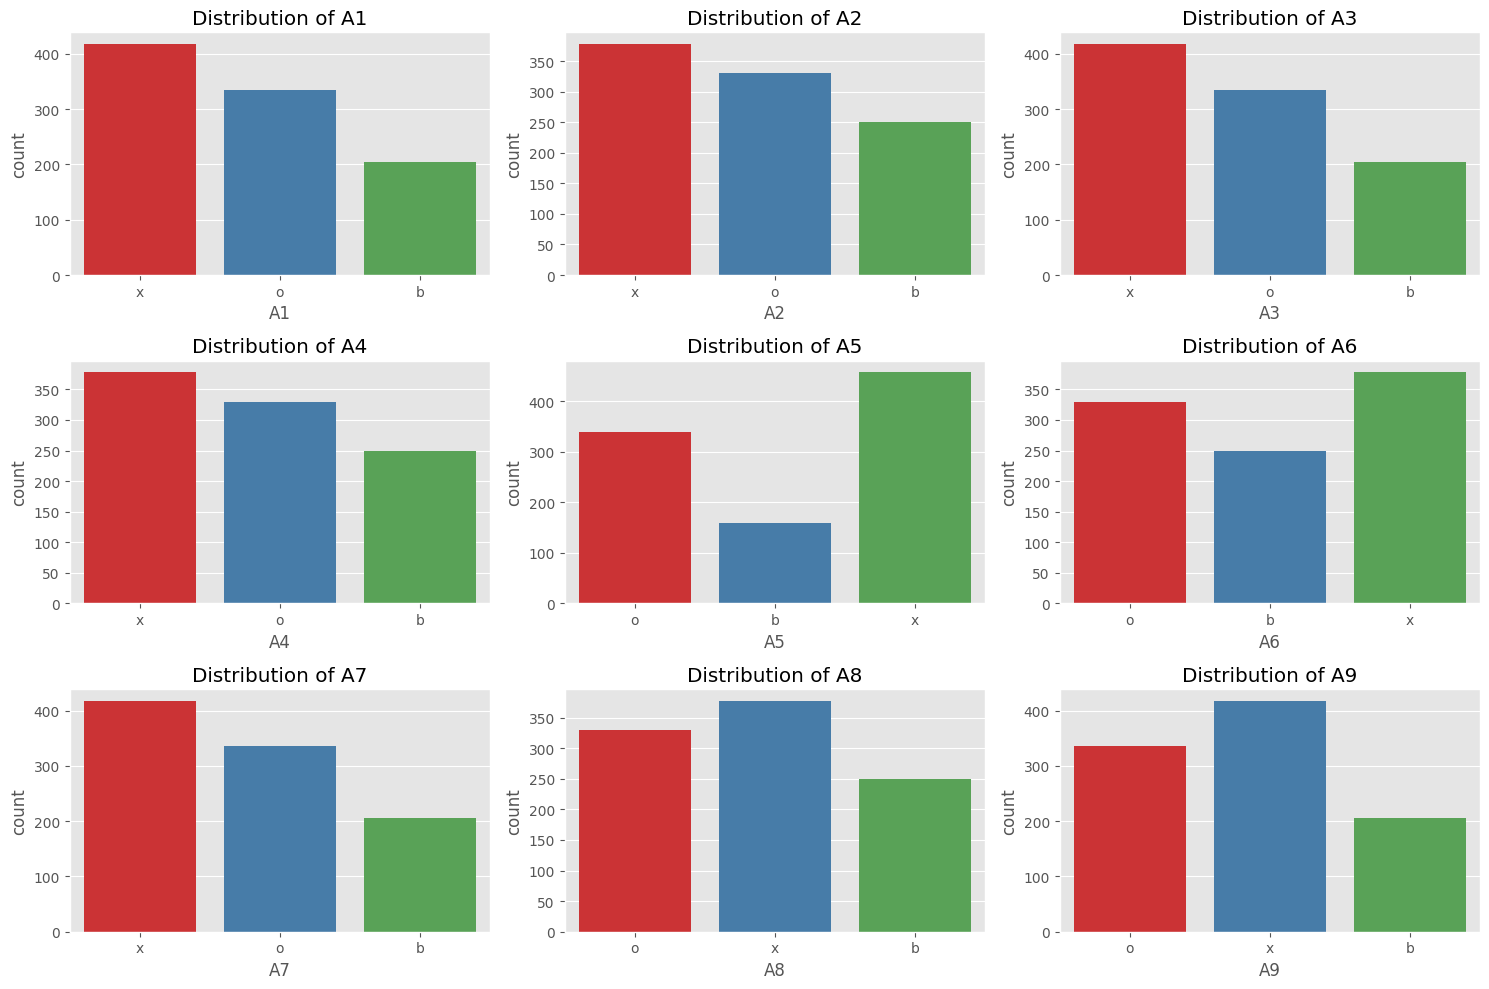

In [8]:
# Distribution of x, o, b marks
fig, axes = plt.subplots(3, 3, figsize=(15, 10))
for i, col in enumerate(df.columns[:-1]):
    sns.countplot(ax=axes[i // 3, i % 3], x=df[col], palette='Set1')
    axes[i // 3, i % 3].set_title(f"Distribution of {col}")
plt.tight_layout()
plt.show()

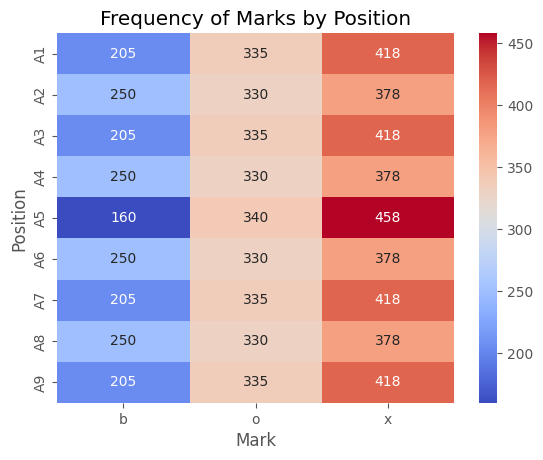

In [9]:
df_melted = df.melt(id_vars='Class', var_name='Position', value_name='Mark')
heatmap_data = df_melted.pivot_table(index='Position', columns='Mark', aggfunc='size', fill_value=0)
sns.heatmap(heatmap_data, annot=True, cmap='coolwarm', fmt='d')
plt.title('Frequency of Marks by Position')
plt.show()

##### Distribution of Classes

C:\Users\Jessica\AppData\Local\Temp\ipykernel_14004\2881481019.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Class', data=df, palette='bright')


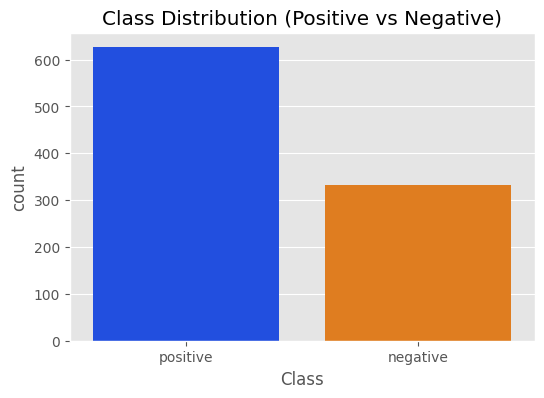

In [10]:
plt.figure(figsize=(6, 4))
sns.countplot(x='Class', data=df, palette='bright')
plt.title('Class Distribution (Positive vs Negative)')
plt.show()

##### Correlation Heatmap

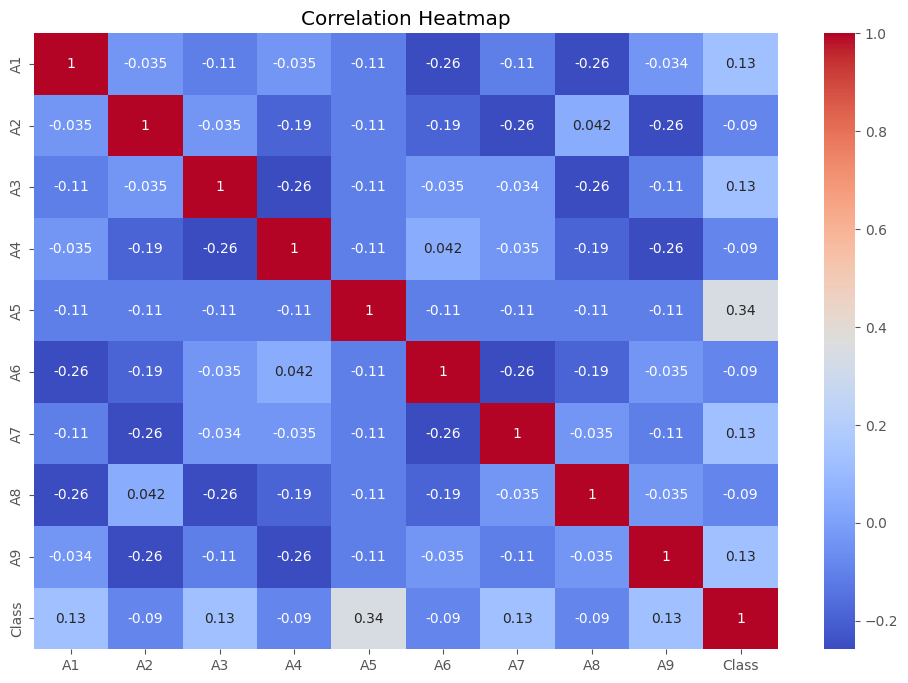

In [11]:
plt.figure(figsize=(12, 8))
sns.heatmap(df_num.corr(), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

##### Pairplot

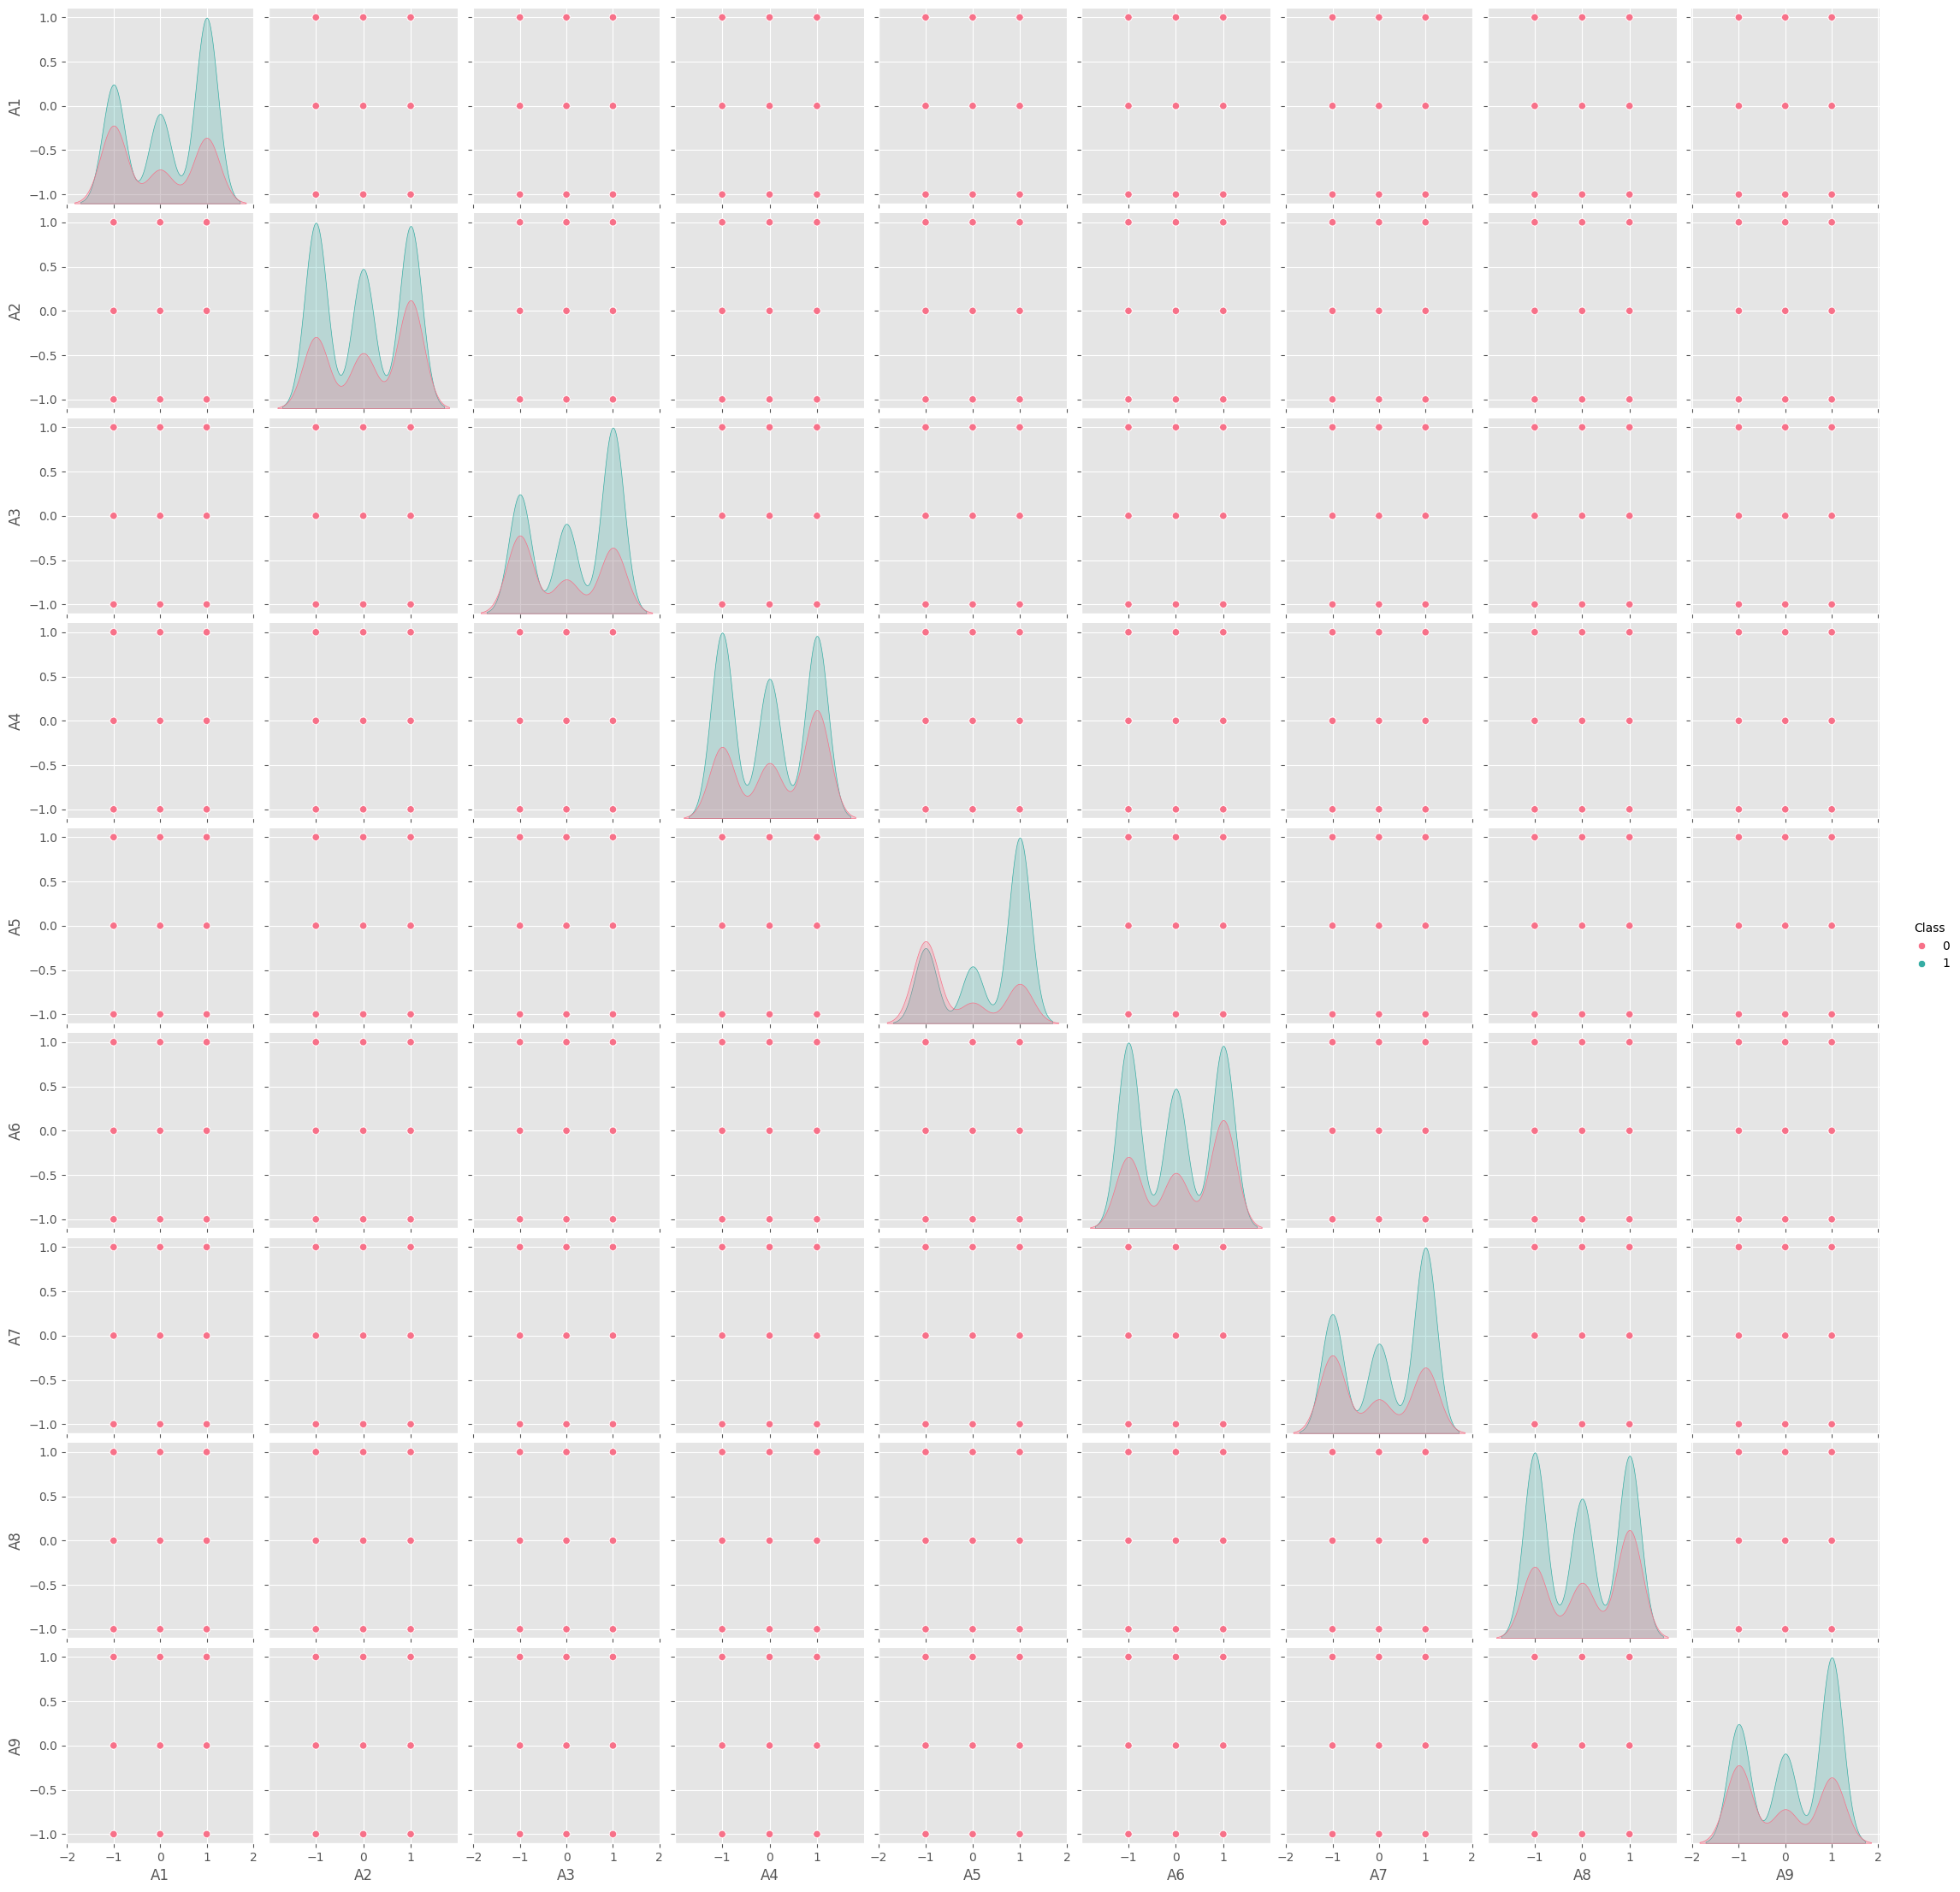

In [12]:
# Pairplot for numerical features
sns.pairplot(df_num, vars=['A1', 'A2', 'A3', 'A4', 'A5', 'A6', 'A7', 'A8', 'A9'], hue='Class', palette='husl')
plt.show()

***
### 

#### 1.3 Splitting the Dataset into Training and Testing Sets

In [13]:
X_training, X_testing, y_training, y_testing = train_test_split(X_scaled, y, test_size=0.2, random_state=42)

#### 1.4 Building and Training the Model

In [14]:
# Build the logistic regression model
model = LogisticRegression(C=.1, max_iter=500)
model.fit(X_training, y_training)

# Predict based on the test dataset
y_pred = model.predict(X_testing)

# Print model coefficients and intercept
print(f'Weight Coefficient: {model.coef_}')
print(f'Bias: {model.intercept_}')


Weight Coefficient: [[1.33056589 1.01553231 1.29617607 1.00121369 1.70866704 0.98392475
  1.34110319 0.93532545 1.343034  ]]
Bias: [0.79348203]


In [15]:
# Calculate accuracy for train and test datasets
print(f'Test accuracy: {model.score(X_testing, y_testing):.2f}')
print(f'Train accuracy: {model.score(X_training, y_training):.2f}')

# Evaluate the model using different metrics
accuracy = accuracy_score(y_testing, y_pred)
precision = precision_score(y_testing, y_pred)
recall = recall_score(y_testing, y_pred)
f1 = f1_score(y_testing, y_pred)

print(f'\nAccuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')

Test accuracy: 0.88
Train accuracy: 0.91

Accuracy: 0.88
Precision: 0.84
Recall: 1.00
F1 Score: 0.91


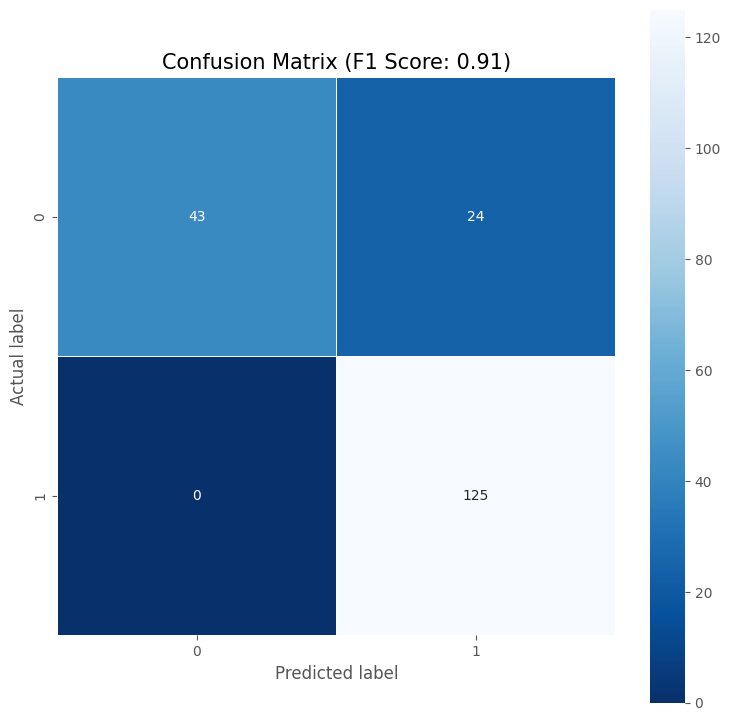

In [16]:
# Generate a confusion matrix
cm = confusion_matrix(y_testing, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(9, 9))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap="Blues_r")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = f'Confusion Matrix (F1 Score: {f1:.2f})'
plt.title(title, size=15)
plt.show()

The confusion matrix shows great model performance in addition to an F1 score of 0.91, but it yielded 24 instances of false positives.

- **ACCURACY** (0.88): The model has pretty high accuracy, having been able to correctly predict 168 labels out of 192.
- **PRECISION** (0.84): There are 24 false positives which is the model incorrectly classifying negative labels as positive, but
- **RECALL** (1.00): The model performed perfectly at detecting positive labels (125/125), it did not miss or wrongly categorize any positive cases. 

To improve the model's predictions, we can make some adjustments. 

##

#### 1.5 Tweaking the Model

The Logistic Regression model consists of several parameters such as:
- **C** - Inverse of *regularization* strength (a method for increasing a model's generalizability—that is, it's ability to produce accurate predictions on new datasets); must be a positive float. Like in support vector machines, smaller values specify stronger regularization.
- **solver** - Algorithm to use in the optimization problem. Default is ‘lbfgs’. For small datasets, ‘liblinear’ is a good choice, whereas ‘sag’ and ‘saga’ are faster for large ones; ‘liblinear’ and ‘newton-cholesky’ can only handle binary classification by default. 
- **max_iter** - Maximum number of iterations taken for the solvers to converge.

`False positive concerns` are usually addressed by manipulating the decision threshold (regularization), which we shall try here.

In [17]:
# Build the logistic regression model, now with C=0.3
model = LogisticRegression(C=0.3, max_iter=500)
model.fit(X_training, y_training)

# Predict based on the test dataset
y_pred = model.predict(X_testing)

# Print model coefficients and intercept
print(f'Weight Coefficient: {model.coef_}')
print(f'Bias: {model.intercept_}')


Weight Coefficient: [[2.41181809 2.12630624 2.38931056 2.10356048 2.78318469 2.07700806
  2.4391707  2.02910441 2.45024904]]
Bias: [0.89096308]


In [18]:
# Calculate accuracy for train and test datasets
print(f'Test accuracy: {model.score(X_testing, y_testing):.2f}')
print(f'Train accuracy: {model.score(X_training, y_training):.2f}')

# Evaluate the model using different metrics
accuracy = accuracy_score(y_testing, y_pred)
precision = precision_score(y_testing, y_pred)
recall = recall_score(y_testing, y_pred)
f1 = f1_score(y_testing, y_pred)

print(f'\nAccuracy: {accuracy:.2f}')
print(f'Precision: {precision:.2f}')
print(f'Recall: {recall:.2f}')
print(f'F1 Score: {f1:.2f}')

Test accuracy: 0.97
Train accuracy: 0.99

Accuracy: 0.97
Precision: 0.95
Recall: 1.00
F1 Score: 0.98


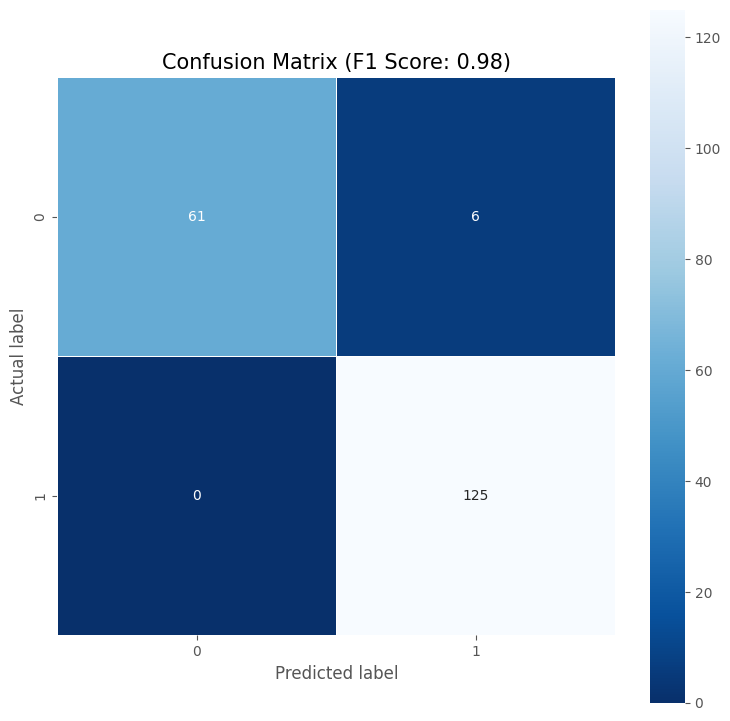

In [19]:
# Generate a confusion matrix
cm = confusion_matrix(y_testing, y_pred)

# Plot the confusion matrix
plt.figure(figsize=(9, 9))
sns.heatmap(cm, annot=True, fmt="d", linewidths=.5, square=True, cmap="Blues_r")
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
title = f'Confusion Matrix (F1 Score: {f1:.2f})'
plt.title(title, size=15)
plt.show()

Raising the `C` from 0.1 to 0.3, which slightly weakened the regularization, raised the model's F1 score to 0.98 as well as its other metric values--such as the accuracy which is now at 0.97 and precision at 0.95--while maintaining the perfect recall. It now only incorrectly identified 6 negative cases as positive. 

Interestingly, raising the C to 1.5 (a considerably weaker regularization) yields the same confusion matrix result, but I just chose to keep it at 0.3. This way, the model's regularization strength is still strong, well-fitting for a simple model handling tic-tac-toe endgame predictions.

##
***

### Checking Out Other Models' Accuracy

##### Perceptron model

In [20]:
from sklearn.linear_model import Perceptron

model = Perceptron()
model.fit(X_training, y_training)


# Making Predictions
predictions = model.predict(X_testing)

# Compute how well we performed
correct = (y_testing == predictions).sum()
incorrect = (y_testing != predictions).sum()
total = len(predictions)

# Print results
print(f"Results for model {type(model).__name__}")
print(f"Correct: {correct}")
print(f"Incorrect: {incorrect}")
print(f"Accuracy: {100 * correct / total:.2f}%")


Results for model Perceptron
Correct: 180
Incorrect: 12
Accuracy: 93.75%


##### Support Vector Classification model

In [21]:
from sklearn import svm

model = svm.SVC()
model.fit(X_training, y_training)

# Making Predictions
predictions = model.predict(X_testing)

# Compute how well we performed
correct = (y_testing == predictions).sum()
incorrect = (y_testing != predictions).sum()
total = len(predictions)

# Print results
print(f"Results for model {type(model).__name__}")
print(f"Correct: {correct}")
print(f"Incorrect: {incorrect}")
print(f"Accuracy: {100 * correct / total:.2f}%")


Results for model SVC
Correct: 188
Incorrect: 4
Accuracy: 97.92%


##### Gaussian Naive Bayes model

In [22]:
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(X_training, y_training)

# Making Predictions
predictions = model.predict(X_testing)

# Compute how well we performed
correct = (y_testing == predictions).sum()
incorrect = (y_testing != predictions).sum()
total = len(predictions)

# Print results
print(f"Results for model {type(model).__name__}")
print(f"Correct: {correct}")
print(f"Incorrect: {incorrect}")
print(f"Accuracy: {100 * correct / total:.2f}%")

Results for model GaussianNB
Correct: 132
Incorrect: 60
Accuracy: 68.75%


##### K-Nearest Neighbors model

In [23]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=1)
model.fit(X_training, y_training)

# Making Predictions
predictions = model.predict(X_testing)

# Compute how well we performed
correct = (y_testing == predictions).sum()
incorrect = (y_testing != predictions).sum()
total = len(predictions)

# Print results
print(f"Results for model {type(model).__name__}")
print(f"Correct: {correct}")
print(f"Incorrect: {incorrect}")
print(f"Accuracy: {100 * correct / total:.2f}%")

Results for model KNeighborsClassifier
Correct: 192
Incorrect: 0
Accuracy: 100.00%
